### Lab 3 notebook: figures and tables for the report

This notebook times the similarity implementations and plots the stability
results. Algorithm 1 itself runs in `algorithm1.py`, this notebook
only reads its output from `../results/S.csv`.

In [1]:
#setup
from pathlib import Path
import timeit

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyreadr
from sklearn.cluster import KMeans

import similarity as sim

DATA_PATH = Path("../data/lingBinary.Rdata")
RESULTS_DIR = Path("../results")
FIG_DIR = Path("../report/figures")
TABLE_DIR = Path("../report/tables")
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
#colors and plot style used by every figure
INK = "#0b0b0b"
INK_SOFT = "#52514e"
GRID = "#e4e3de"
VERSION_COLORS = {
    "Pure Python, O(q^2)": "#2a78d6",
    "NumPy blocks, O(q^2)": "#eb6834",
    "Table + NumPy, O(q + k^2)": "#1baf7a",
    "Table + Numba, O(q + k^2)": "#eda100",
}
#one blue ramp, light to dark, for the ordered values k = 2..10
K_COLORS = dict(zip(range(2, 11), [
    "#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6",
    "#256abf", "#1c5cab", "#184f95", "#104281"]))

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK_SOFT,
    "xtick.color": INK_SOFT, "ytick.color": INK_SOFT,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.axisbelow": True,
})

In [3]:
#load the binary columns
#keep only the binary question columns (the Q... columns)
ling = pyreadr.read_r(str(DATA_PATH))["lingBinary"]
question_cols = [c for c in ling.columns if c.startswith("Q")]
X = ling[question_cols].to_numpy(dtype=np.float32)
print(X.shape, "values:", np.unique(X))

(45152, 468) values: [0. 1.]


In [4]:
#timing the similarity versions
#subsample fractions to time; q is the number of shared points.
M_VALUES = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
NAIVE_MAX_M = 0.5   # pure Python is too slow beyond this
K_TIMING = 10

In [5]:
def make_membership_pair(data, m, k, seed):
    """Cluster two subsamples; return labels on the points they share."""
    rng = np.random.default_rng(seed)
    n_points = data.shape[0]
    n_sub = int(round(m * n_points))
    labels = []
    for _ in range(2):
        rows = rng.choice(n_points, size=n_sub, replace=False)
        model = KMeans(n_clusters=k, n_init=1,
                       random_state=int(rng.integers(2**31 - 1)))
        full = np.full(n_points, -1, dtype=np.int64)
        full[rows] = model.fit_predict(data[rows])
        labels.append(full)
    shared = (labels[0] >= 0) & (labels[1] >= 0)
    return labels[0][shared], labels[1][shared]


pairs = {m: make_membership_pair(X, m, K_TIMING, seed=215) for m in M_VALUES}
for m, (a, b) in pairs.items():
    print(f"m={m}: q={a.size}")

m=0.2: q=1788
m=0.3: q=4096
m=0.4: q=7213
m=0.5: q=11279
m=0.6: q=16261
m=0.7: q=22136
m=0.8: q=28965


In [6]:
# All versions must give the same value before we compare their speed.
VERSIONS = {
    "Pure Python, O(q^2)": sim.similarity_naive_python,
    "NumPy blocks, O(q^2)": sim.similarity_blocked_numpy,
    "Table + NumPy, O(q + k^2)": sim.similarity_table_numpy,
    "Table + Numba, O(q + k^2)": sim.similarity_table_numba,
}
a, b = pairs[0.2]
values = {name: f(a, b) for name, f in VERSIONS.items()}
print(values)
assert max(values.values()) - min(values.values()) < 1e-12

{'Pure Python, O(q^2)': np.float64(0.28849329569513055), 'NumPy blocks, O(q^2)': np.float64(0.28849329569513055), 'Table + NumPy, O(q + k^2)': 0.28849329569513055, 'Table + Numba, O(q + k^2)': 0.28849329569513055}


In [7]:
def seconds_per_call(func, a, b):
    """Average seconds per call; one call only if it takes over a second."""
    start = timeit.default_timer()
    func(a, b)                       # warm-up (compiles Numba code)
    first_call = timeit.default_timer() - start
    if first_call > 1.0:
        return first_call
    timer = timeit.Timer(lambda: func(a, b))
    number, _ = timer.autorange()
    return min(timer.repeat(repeat=3, number=number)) / number


rows = []
for m, (a, b) in pairs.items():
    for name, func in VERSIONS.items():
        if name.startswith("Pure Python") and m > NAIVE_MAX_M:
            continue
        rows.append({"m": m, "q": a.size, "version": name,
                     "seconds_per_call": seconds_per_call(func, a, b)})
timing = pd.DataFrame(rows)
timing.to_csv(TABLE_DIR / "similarity_timing.csv", index=False)
timing.pivot(index="m", columns="version", values="seconds_per_call")

version,"NumPy blocks, O(q^2)","Pure Python, O(q^2)","Table + NumPy, O(q + k^2)","Table + Numba, O(q + k^2)"
m,,,,
0.2,0.002194,0.322541,0.000009,0.000003
0.3,0.004939,1.699396,0.000014,0.000006
0.4,0.015653,5.317611,0.000021,0.000009
0.5,0.041031,13.848426,0.000033,0.000013
0.6,0.091718,NaN,0.000046,0.000018
0.7,0.116443,NaN,0.000058,0.000024
0.8,0.199022,NaN,0.000069,0.000031


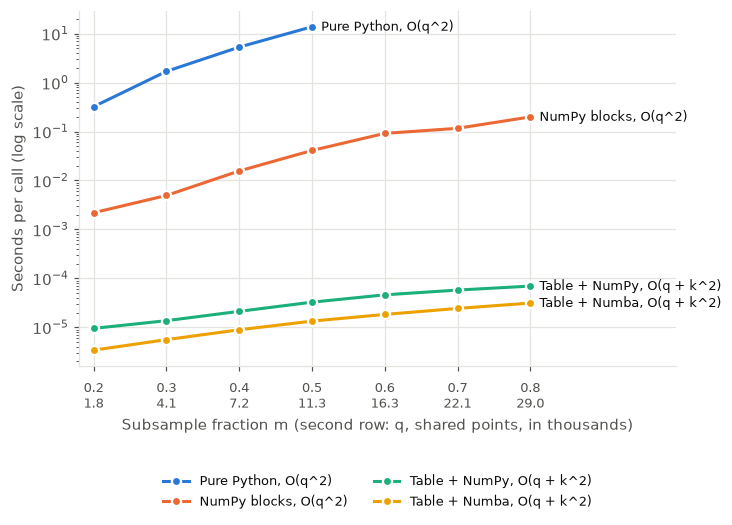

In [8]:
# Figure: time per call against m, log scale, one line per version.
fig, ax = plt.subplots(figsize=(7, 4.2))
for name, color in VERSION_COLORS.items():
    part = timing[timing["version"] == name]
    ax.plot(part["m"], part["seconds_per_call"], color=color, lw=2,
            marker="o", ms=6, mec="white", mew=1.5, label=name)
    last = part.iloc[-1]
    ax.annotate(name, (last["m"], last["seconds_per_call"]),
                xytext=(6, 0), textcoords="offset points", va="center",
                fontsize=8.5, color=INK)
ax.set_yscale("log")
q_by_m = timing.groupby("m")["q"].first()
ax.set_xticks(M_VALUES)
ax.set_xticklabels([f"{m}\n{q_by_m[m] / 1000:.1f}" for m in M_VALUES])
ax.tick_params(axis="x", labelsize=8.5, pad=6)
ax.set_xlim(0.18, 1.0)
ax.set_xlabel("Subsample fraction m (second row: q, shared points, in thousands)")
ax.set_ylabel("Seconds per call (log scale)")
ax.legend(frameon=False, fontsize=8.5, loc="upper center",
          bbox_to_anchor=(0.5, -0.27), ncol=2)
fig.savefig(FIG_DIR / "similarity_timing.png")
plt.show()

In [9]:
#stability results from Algorithm 1
#S has one row per repetition and one column per k.
S = pd.read_csv(RESULTS_DIR / "S.csv")
S.columns = [int(c[1:]) for c in S.columns]
print(S.shape, "missing:", int(S.isna().sum().sum()))
summary = S.describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
summary.index.name = "k"
summary.round(4).to_csv(TABLE_DIR / "similarity_summary_by_k.csv")
summary.round(3)

(100, 9) missing: 0


,mean,std,min,25%,50%,75%,max
k,,,,,,,
2,0.742,0.215,0.344,0.583,0.667,0.949,0.995
3,0.957,0.027,0.898,0.930,0.969,0.979,0.991
4,0.692,0.202,0.336,0.457,0.762,0.874,0.977
5,0.629,0.166,0.330,0.468,0.625,0.780,0.957
6,0.505,0.110,0.307,0.427,0.505,0.543,0.846
7,0.416,0.077,0.291,0.366,0.405,0.448,0.761
8,0.379,0.086,0.253,0.317,0.360,0.413,0.653
9,0.369,0.074,0.231,0.320,0.359,0.410,0.619
10,0.366,0.074,0.240,0.317,0.355,0.405,0.590


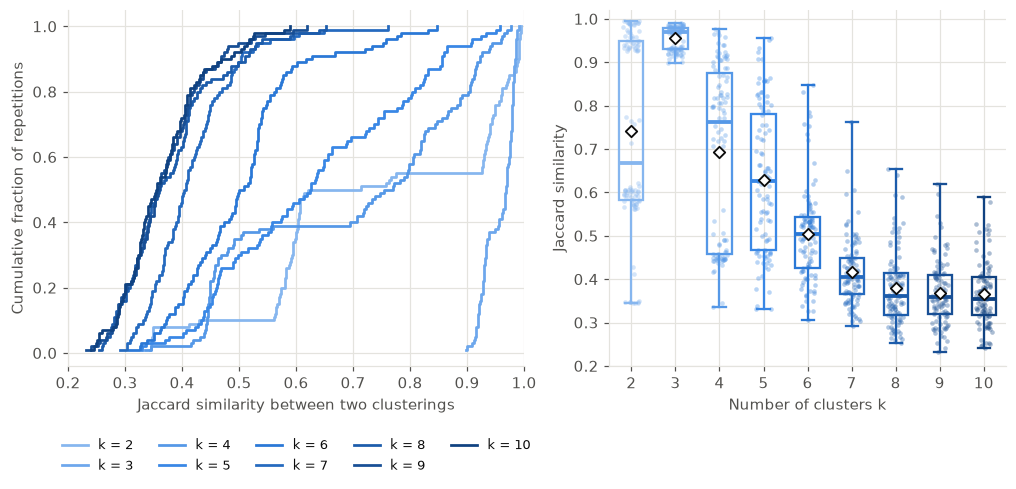

In [10]:
#figure: ECDF (Empirical Cumulative Distribution Function) per k (left) and spread of similarity per k (right).
fig, (ax_cdf, ax_box) = plt.subplots(1, 2, figsize=(11, 4.2),
                                     gridspec_kw={"width_ratios": [1.15, 1]})
for k in S.columns:
    values = np.sort(S[k].to_numpy())
    cdf = np.arange(1, values.size + 1) / values.size
    ax_cdf.step(values, cdf, where="post", color=K_COLORS[k], lw=1.8,
                label=f"k = {k}")
ax_cdf.set_xlabel("Jaccard similarity between two clusterings")
ax_cdf.set_ylabel("Cumulative fraction of repetitions")
ax_cdf.set_xlim(0.2, 1.0)
ax_cdf.legend(frameon=False, fontsize=8.5, ncol=5, loc="upper center",
              bbox_to_anchor=(0.5, -0.17))

rng = np.random.default_rng(0)
for k in S.columns:
    values = S[k].to_numpy()
    ax_box.boxplot(values, positions=[k], widths=0.55, showfliers=False,
                   patch_artist=True, whis=(0, 100),
                   boxprops=dict(facecolor="none", edgecolor=K_COLORS[k], lw=1.5),
                   whiskerprops=dict(color=K_COLORS[k], lw=1.5),
                   capprops=dict(color=K_COLORS[k], lw=1.5),
                   medianprops=dict(color=K_COLORS[k], lw=2.5))
    ax_box.scatter(k + rng.uniform(-0.18, 0.18, values.size), values,
                   s=9, color=K_COLORS[k], alpha=0.35, linewidths=0)
    ax_box.scatter([k], [values.mean()], marker="D", s=28, color="white",
                   edgecolor=INK, linewidths=1.2, zorder=5)
ax_box.set_xticks(list(S.columns))
ax_box.set_xlabel("Number of clusters k")
ax_box.set_ylabel("Jaccard similarity")
ax_box.set_ylim(0.2, 1.02)
fig.savefig(FIG_DIR / "stability_by_k.png")
plt.show()

In [11]:
#runtime of the hpc runs
#settings and elapsed time from the two Algorithm 1 runs.
runs = [pd.read_csv(RESULTS_DIR / "run_info.csv")]
outer_path = Path("../results_outer/run_info.csv")
if outer_path.exists():
    runs.append(pd.read_csv(outer_path))
runtime = pd.concat(runs, ignore_index=True)
runtime.to_csv(TABLE_DIR / "algorithm1_runtime.csv", index=False)
runtime

,m,B,k_max,loop,n_jobs,n_init,seed,elapsed_seconds
0,0.8,100,10,inner,24,1,215,225.5
1,0.8,100,10,outer,24,1,215,511.7
